# Batch 7: direct comparison with Ghezzi's thesis (2-DOF, closed loop)
Ghezzi (PoliMi 2021) identified three linear grey-box models of the ANT-X 2-DOF rig with MATLAB `greyest` (output error) on closed-loop step flights, scored with VAF. We repeat each one on our flights, run his published constants on our data, and add PINC and plain NN.

| Ghezzi model | input -> output | his constants (fleet mean) | his VAF |
|---|---|---|---|
| closed-loop attitude | pitch setpoint -> pitch | wn 16.16, xi 0.56 | pitch 99.86, rate 97.27 |
| closed-loop position | x setpoint -> x | wn 3.47, xi 0.84 | x 99.45, acceleration 58.72 |
| open-loop longitudinal | motor command -> u, q, pitch, x | Xu -0.027, Xq 0.70, Mq -7.53, Xdelta 98.29, Mdelta 5.56 | x 96.07 |

Closed-loop model (both): y'' = wn^2 (r(t - tau) - y) - 2 xi wn y'   (r = setpoint, tau = delay, fitted).

Flights: attitude: train attitude_doublet_1, 3, test attitude_doublet_4, 5 (window 1 s before the doublet to 3 s after; the rest of these flights is position hold). Position: train position_1, 3, test position_2 (whole flight). Data: Amr's clean files at 50 Hz.

## 0. Setup

In [1]:
import numpy as np, pandas as pd, torch, time, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.signal import savgol_filter
torch.set_num_threads(4)
D = '../data/clean/2dof/'
DT = 0.02; SEEDS = [0, 1, 2, 3, 4]; EPOCHS = 10000
grid = lambda n: pd.read_csv(D + n + '.csv').iloc[::5].reset_index(drop=True)      # 50 Hz
def att_window(f):
    k = np.flatnonzero(np.abs(f.theta_sp.values) > 0.05)[0]; t0 = f.t[k]
    return f[(f.t >= t0 - 1) & (f.t < t0 + 3)].reset_index(drop=True)
TASKS = {
 'CL attitude': dict(y='theta', yd='q', r='theta_sp', train=['attitude_doublet_1', 'attitude_doublet_3'],
                     test=['attitude_doublet_4', 'attitude_doublet_5'], cut=att_window, thesis=(16.16, 0.56, 0.0),
                     thesis_vaf='pitch 99.86, rate 97.27'),
 'CL position': dict(y='x', yd='v', r='x_sp', train=['position_1', 'position_3'], test=['position_2'],
                     cut=lambda f: f, thesis=(3.47, 0.84, 0.0), thesis_vaf='x 99.45, acc 58.72')}
F = {n: cfg['cut'](grid(n)) for cfg in TASKS.values() for n in cfg['train'] + cfg['test']}
vaf = lambda y, yh: max(1 - np.var(y - yh) / np.var(y), 0) * 100
acc = lambda v: savgol_filter(v, 25, 2, deriv=1, delta=DT)          # smoothed derivative

## 1. Physics, written once, and the grey-box simulation

In [2]:
def accel(y, yd, r, p):
    wn, xi = p[0], p[1]
    return wn**2 * (r - y) - 2 * xi * wn * yd

def run_ivp(p, f, c):
    t, R = f.t.values, f[c['r']].values
    rhs = lambda tt, z: [z[1], accel(z[0], z[1], np.interp(tt - p[2], t, R), p)]
    return solve_ivp(rhs, (t[0], t[-1]), [f[c['y']][0], f[c['yd']][0]], t_eval=t, max_step=0.005, rtol=1e-8, atol=1e-10).y

def grey_fit(c):
    res = lambda p: np.concatenate([run_ivp(p, F[n], c)[0] - F[n][c['y']].values for n in c['train']])
    r = least_squares(res, list(c['thesis'][:2]) + [0.02], bounds=([0.5, 0, 0], [60, 3, 0.3]), diff_step=1e-3)
    J = r.jac; s2 = (r.fun**2).sum() / (len(r.fun) - 3)
    return r.x, np.sqrt(np.diag(s2 * np.linalg.inv(J.T @ J)))

## 2. Network, step, training, rollout (same design as Batch 6: output = change per step)

In [3]:
def mlp(n_in, n_out, width=32, depth=3):
    layers, n = [], n_in
    for _ in range(depth):
        layers += [torch.nn.Linear(n, width), torch.nn.Tanh()]; n = width
    return torch.nn.Sequential(*layers, torch.nn.Linear(n, n_out))
col = lambda x: torch.tensor(np.asarray(x), dtype=torch.float32).reshape(-1, 1)

def pairs(names, c):
    out = []
    for n in names:
        f = F[n]; y, yd, r = f[c['y']].values, f[c['yd']].values, f[c['r']].values
        out.append(np.column_stack([y[1:-1], yd[1:-1], r[1:-1], r[:-2], y[2:], yd[2:]]))
    return np.vstack(out)

def pinc_model(net, sc):
    def step(y, yd, r, rp, dt):
        x = torch.cat([(y - sc['m'][0]) / sc['s'][0], (yd - sc['m'][1]) / sc['s'][1],
                       (r - sc['m'][2]) / sc['s'][2], (rp - sc['m'][3]) / sc['s'][3], dt / DT], 1)
        o = net(x)
        return y + sc['d'][0] * o[:, :1], yd + sc['d'][1] * o[:, 1:2]
    return step

def train_pinc(c, p, seed=0, epochs=EPOCHS, lr=1e-3, w_phys=1.0, n_col=2000):
    # data
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    A = pairs(c['train'], c)
    sc = dict(m=A[:, :4].mean(0), s=A[:, :4].std(0) + 1e-6, d=(A[:, 4:6] - A[:, :2]).std(0))
    y0, v0, r0, rp0, y1, v1 = [col(A[:, i]) for i in range(6)]
    lo, hi = A[:, :4].min(0), A[:, :4].max(0); pad = 0.2 * (hi - lo)
    # network
    net = mlp(5, 2); step = pinc_model(net, sc)
    # optimizer
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs, eta_min=lr / 20)
    # loop
    for e in range(epochs):
        a, b = step(y0, v0, r0, rp0, torch.full_like(y0, DT))
        data = (((a - y1) / sc['d'][0])**2).mean() + (((b - v1) / sc['d'][1])**2).mean()
        a, b = step(y0, v0, r0, rp0, torch.zeros_like(y0))
        start = (((a - y0) / sc['d'][0])**2).mean() + (((b - v0) / sc['d'][1])**2).mean()
        physics = torch.tensor(0.0)
        if w_phys > 0:
            z = [col(rng.uniform(lo[i] - pad[i], hi[i] + pad[i], n_col)) for i in range(4)]
            dt = col(rng.uniform(0, DT, n_col)).requires_grad_(True)
            a, b = step(*z, dt)
            da = torch.autograd.grad(a, dt, torch.ones_like(a), create_graph=True)[0]
            db = torch.autograd.grad(b, dt, torch.ones_like(b), create_graph=True)[0]
            w = min(p[2] / DT, 1.0)                                         # delayed setpoint inside the step
            rt = z[2] - w * (1 - dt / DT) * (z[2] - z[3])
            physics = (((da - b) * DT / sc['d'][0])**2).mean() + (((db - accel(a, b, rt, p)) * DT / sc['d'][1])**2).mean()
        loss = data + start + w_phys * physics
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return dict(step=step, last=dict(data=data.item(), start=start.item(), physics=physics.item()))

def run_open(step, f, c):
    y, yd, r = f[c['y']].values, f[c['yd']].values, f[c['r']].values
    a, b = y[1], yd[1]; Y, V = [y[0], a], [yd[0], b]
    with torch.no_grad():
        for k in range(1, len(f) - 1):
            a, b = step(col([a]), col([b]), col([r[k]]), col([r[k - 1]]), col([DT])); a, b = a.item(), b.item()
            Y.append(a); V.append(b)
    return np.array(Y), np.array(V)

## 3. Fit, train and score both tasks

In [4]:
rows, consts, preds = [], [], {}
for task, c in TASKS.items():
    t0 = time.time(); p, sd = grey_fit(c)
    consts.append(dict(task=task, model='Ghezzi thesis (published)', wn=c['thesis'][0], xi=c['thesis'][1], tau='-'))
    consts.append(dict(task=task, model='grey-box refit on our flights', wn=f'{p[0]:.3f} +- {sd[0]:.3f}', xi=f'{p[1]:.3f} +- {sd[1]:.3f}', tau=f'{p[2]:.3f} +- {sd[2]:.3f}'))
    print(task, 'grey-box', p.round(3), '+-', sd.round(3), f'({time.time() - t0:.0f} s)')
    R = {}
    for label, wp in [('PINC', 1.0), ('plain NN', 0.0)]:
        R[label] = []
        for s in SEEDS:
            t0 = time.time(); r = train_pinc(c, p, seed=s, w_phys=wp); R[label].append(r)
            print(' ', label, 'seed', s, f'{time.time() - t0:.0f} s', {k: round(v, 6) for k, v in r['last'].items()})
    for n in c['test']:
        f = F[n]; y, yd = f[c['y']].values, f[c['yd']].values
        def score(Y, V): return [vaf(y, Y), vaf(yd, V), vaf(acc(yd), acc(V))]
        for label, pp in [('Ghezzi constants', c['thesis']), ('grey-box refit (ours)', p)]:
            Y, V = run_ivp(pp, f, c); preds[(n, label)] = [Y]
            rows.append(dict(task=task, test=n, model=label, **dict(zip(['VAF y', 'VAF rate', 'VAF acc'], score(Y, V)))))
        for label in ['PINC', 'plain NN']:
            S_ = []; preds[(n, label)] = []
            for r in R[label]:
                Y, V = run_open(r['step'], f, c); S_.append(score(Y, V)); preds[(n, label)].append(Y)
            S_ = np.array(S_)
            rows.append(dict(task=task, test=n, model=label + ' (5 seeds)', **{k: f'{m:.2f} +- {s:.2f}' for k, m, s in zip(['VAF y', 'VAF rate', 'VAF acc'], S_.mean(0), S_.std(0))}))
T = pd.DataFrame(rows); T.to_csv('../results/batch7_ghezzi_comparison.csv', index=False)
K = pd.DataFrame(consts); K.to_csv('../results/batch7_ghezzi_constants.csv', index=False)
print('Thesis VAF:', {k: c['thesis_vaf'] for k, c in TASKS.items()})
display(K); T.round(2)

CL attitude grey-box [2.7387e+01 9.4700e-01 2.2000e-02] +- [1.563 0.037 0.002] (4 s)


  PINC seed 0 49 s {'data': 0.176883, 'start': 0.016401, 'physics': 0.057204}


  PINC seed 1 47 s {'data': 0.192526, 'start': 0.016787, 'physics': 0.069995}


  PINC seed 2 47 s {'data': 0.195509, 'start': 0.017138, 'physics': 0.058457}


  PINC seed 3 46 s {'data': 0.187304, 'start': 0.017565, 'physics': 0.052119}


  PINC seed 4 48 s {'data': 0.193912, 'start': 0.017302, 'physics': 0.053398}


... (15 outputs left out)

  plain NN seed 4 22 s {'data': 0.064898, 'start': 3.1e-05, 'physics': 0.0}


Thesis VAF: {'CL attitude': 'pitch 99.86, rate 97.27', 'CL position': 'x 99.45, acc 58.72'}


,task,model,wn,xi,tau
0,CL attitude,Ghezzi thesis (published),16.16,0.56,-
1,CL attitude,grey-box refit on our flights,27.387 +- 1.563,0.947 +- 0.037,0.022 +- 0.002
2,CL position,Ghezzi thesis (published),3.47,0.84,-
3,CL position,grey-box refit on our flights,2.265 +- 0.102,1.132 +- 0.038,0.003 +- 0.016


,task,test,model,VAF y,VAF rate,VAF acc
0,CL attitude,attitude_doublet_4,Ghezzi constants,98.250052,84.195629,93.711181
1,CL attitude,attitude_doublet_4,grey-box refit (ours),99.459714,86.290152,97.393427
2,CL attitude,attitude_doublet_4,PINC (5 seeds),99.31 +- 0.03,87.61 +- 0.22,96.97 +- 0.07
3,CL attitude,attitude_doublet_4,plain NN (5 seeds),99.66 +- 0.02,96.17 +- 0.15,98.89 +- 0.07
4,CL attitude,attitude_doublet_5,Ghezzi constants,98.48543,87.57909,94.788125
5,CL attitude,attitude_doublet_5,grey-box refit (ours),99.598253,89.704636,97.536809
6,CL attitude,attitude_doublet_5,PINC (5 seeds),99.40 +- 0.03,90.44 +- 0.12,96.86 +- 0.04
7,CL attitude,attitude_doublet_5,plain NN (5 seeds),99.59 +- 0.01,95.91 +- 0.07,98.35 +- 0.11
8,CL position,position_2,Ghezzi constants,92.87533,27.547152,0
9,CL position,position_2,grey-box refit (ours),99.284411,91.796916,68.5381


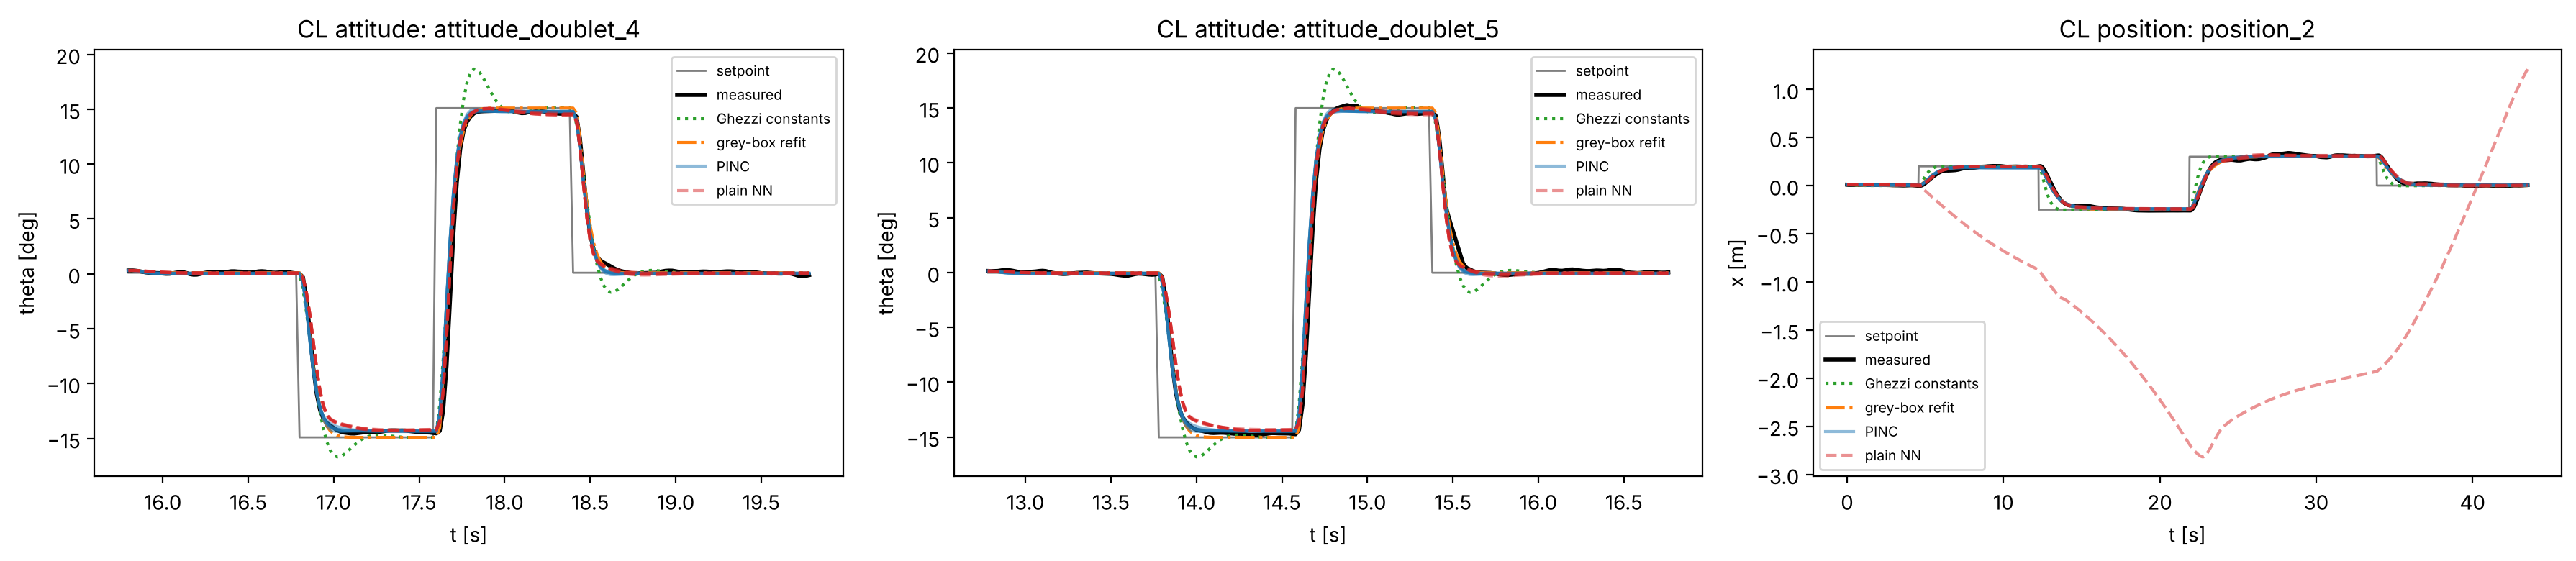

In [5]:
tests = [(task, n) for task, c in TASKS.items() for n in c['test']]
fig, ax = plt.subplots(1, len(tests), figsize=(6 * len(tests), 4))
for a, (task, n) in zip(ax, tests):
    c = TASKS[task]; f = F[n]; k = np.degrees if c['y'] == 'theta' else (lambda z: z)
    a.plot(f.t, k(f[c['r']]), color='gray', lw=1, label='setpoint')
    a.plot(f.t, k(f[c['y']]), 'k', lw=2, label='measured')
    a.plot(f.t, k(preds[(n, 'Ghezzi constants')][0]), ':', color='C2', label='Ghezzi constants')
    a.plot(f.t, k(preds[(n, 'grey-box refit (ours)')][0]), '-.', color='C1', label='grey-box refit')
    for label, color, ls in [('PINC', 'C0', '-'), ('plain NN', 'C3', '--')]:
        for i, Y in enumerate(preds[(n, label)]): a.plot(f.t, k(Y), ls, color=color, alpha=0.5, label=label if i == 0 else None)
    a.set(title=f'{task}: {n}', xlabel='t [s]', ylabel='theta [deg]' if c['y'] == 'theta' else 'x [m]'); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig('../figures/batch7_ghezzi_comparison.png', dpi=120, bbox_inches='tight'); plt.show()

## 4. Open-loop longitudinal model (Ghezzi's third model)
u' = Xu u + Xq q - g theta + Xdelta delta, q' = Mq q + Mdelta delta, theta' = q, x' = u, with delta = our M (front - back motor).
This model has no pitch stiffness, so on closed-loop flights a pure open-loop simulation drifts away within seconds. We therefore fit and score it on 2 s windows, each restarted from the measured state (train position_1, 3, test position_2).

In [6]:
G = 9.81
def ol(p, f, i0, n):
    Xu, Xq, Mq, Xd, Md = p; t, M = f.t.values, f.M.values
    rhs = lambda tt, z: [Xu * z[0] + Xq * z[1] - G * z[2] + Xd * np.interp(tt, t, M), Mq * z[1] + Md * np.interp(tt, t, M), z[1], z[0]]
    y = solve_ivp(rhs, (t[i0], t[i0 + n - 1]), [f.v[i0], f.q[i0], f.theta[i0], f.x[i0]], t_eval=t[i0:i0 + n], max_step=0.02).y
    return y if y.shape[1] == n else np.full((4, n), 1e3)
def run_windows(p, f, L=100):
    Y, R = [], []
    for i in range(0, len(f) - L, L):
        Y.append(ol(p, f, i, L)); R.append(np.vstack([f.v[i:i + L], f.q[i:i + L], f.theta[i:i + L], f.x[i:i + L]]))
    return np.hstack(Y), np.hstack(R)
OLF = {n: grid(n) for n in ['position_1', 'position_3', 'position_2']}
sc = np.array([0.05, 0.3, 0.03, 0.05])
res = lambda p: np.clip(np.concatenate([((lambda Y, R: ((Y - R) / sc[:, None]).ravel())(*run_windows(p, OLF[n]))) for n in ['position_1', 'position_3']]), -1e3, 1e3)
THESIS_OL = [-0.027, 0.70, -7.53, 98.29, 5.56]
r = least_squares(res, THESIS_OL, diff_step=1e-3, max_nfev=200)
ol_rows = []
for label, p in [('Ghezzi constants', THESIS_OL), ('refit on our flights', r.x)]:
    Y, R = run_windows(p, OLF['position_2'])
    ol_rows.append(dict(model=label, **dict(zip(['Xu', 'Xq', 'Mq', 'Xdelta', 'Mdelta'], np.round(p, 3))),
                        **{f'VAF {k}': round(vaf(R[i], Y[i]), 1) for i, k in enumerate(['u', 'q', 'theta', 'x'])}))
OL = pd.DataFrame(ol_rows); OL.to_csv('../results/batch7_ghezzi_openloop.csv', index=False); OL

,model,Xu,Xq,Mq,Xdelta,Mdelta,VAF u,VAF q,VAF theta,VAF x
0,Ghezzi constants,-0.027,0.700,-7.530,98.290,5.560,0,0.0,0,0.0
1,refit on our flights,-10.225,18.493,-17.904,-20.098,8.346,0,16.2,0,77.2


## 5. What this shows
- Closed-loop attitude and position: the same model, method and score as the thesis, on our rig, next to his published numbers; PINC and plain NN on the same task and flights.
- Open-loop longitudinal: his structure does not fit our logs (see the VAF); likely reasons: our M is the front-minus-back motor command, not his normalised delta, and our rig has pitch stiffness (wn about 4 rad/s, Batch 1) that his model lacks.